# Roteiro 7 - Regressão Polinomial

Este é o Roteiro da sétima aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

- Autor: Raoni F. S. Teixeira - raoni.teixeira@ufmt.br
______________________________

Carregue os pacotes

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Regressão Polinomial

Vamos começar com dados gerados aleatoriamente a partir da função \( \sin(2\pi x) \).

O código abaixo gera uma figura com os dados gerados (pontos) e a curva da função teórica \( \sin(2\pi x) \).


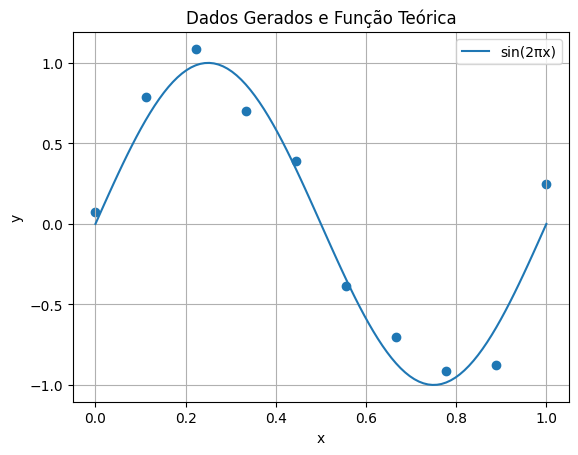

In [ ]:
# Parâmetros para geração dos dados
M = 10  # Número de pontos de dados gerados
NR = 100  # Número de pontos usados para plotar a curva suave

# Geração dos dados de treinamento
x = np.linspace(0, 1, M)  # Pontos espaçados uniformemente no intervalo [0, 1]
y = np.sin(2 * np.pi * x) + np.random.normal(0, 0.15, M)  # Adiciona ruído gaussiano (média 0, desvio padrão 0.15)

# Geração dos dados para a curva teórica
xr = np.linspace(0, 1, NR)  # Pontos espaçados uniformemente para a curva suave
yn = np.sin(2 * np.pi * xr)  # Valores da função seno sem ruído

line, = plt.plot(xr, yn, label='sin(2πx)')  # Plota a curva teórica
plt.scatter(x, y, label='Dados com ruído')  # Plota os pontos de dados com ruído
plt.legend(handles=[line])  # Adiciona a legenda ao gráfico
plt.xlabel('x')  # Rótulo do eixo x
plt.ylabel('y')  # Rótulo do eixo y
plt.title('Dados Gerados e Função Teórica')  # Título do gráfico
plt.grid(True)  # Adiciona uma grade ao gráfico
plt.show()  # Exibe o gráfico


O código abaixo mostra um modelo polinômial com grau $K=9$ que se ajusta perfeitamente aos dados de treinamento e não captura o padrão da função $\text{sin}(2\pi)$. Esse comportamente é chamado de **overfitting**.

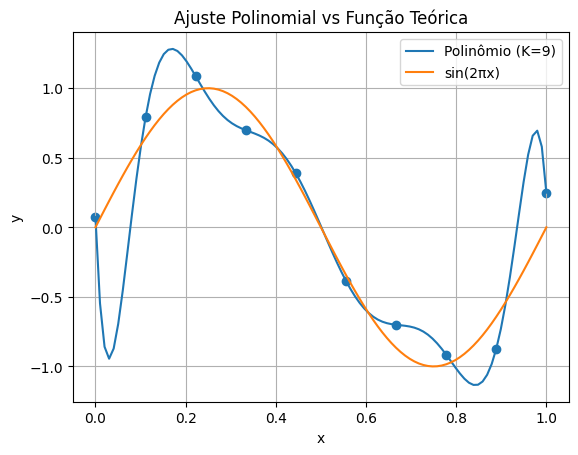

In [ ]:
# Parâmetros para geração da curva teórica
NR = 100  # Número de pontos para a curva suave
xr = np.linspace(0, 1, NR)  # Pontos espaçados uniformemente no intervalo [0, 1]
yr = np.sin(2 * np.pi * xr)  # Valores da função seno sem ruído

# Grau do polinômio para ajuste
K = 9  # Grau do polinômio usado na regressão polinomial

# Ajuste do modelo polinomial aos dados
polynomial_model = np.poly1d(np.polyfit(x, y, K))  # Cria um modelo polinomial de grau K

# Plotagem dos resultados
line1, = plt.plot(xr, polynomial_model(xr), label='Polinômio (K=9)')  # Plota a curva do polinômio ajustado
line2, = plt.plot(xr, yr, label='sin(2πx)')  # Plota a curva teórica da função seno
plt.scatter(x, y, label='Dados com ruído')  # Plota os pontos de dados com ruído

# Configurações do gráfico
plt.legend(handles=[line1, line2])  # Adiciona a legenda ao gráfico
plt.xlabel('x')  # Rótulo do eixo x
plt.ylabel('y')  # Rótulo do eixo y
plt.title('Ajuste Polinomial vs Função Teórica')  # Título do gráfico
plt.grid(True)  # Adiciona uma grade ao gráfico
plt.show()  # Exibe o gráfico

# Regularização

Uma das maneiras de lidar com overfitting é regularizar o modelo.

A regularização \(L2\) (ou *ridge regression*) modifica a função de custo da seguinte forma:

$J(\theta) = \frac{1}{2M} \sum_{i=1}^M (h_\theta(x^{(i)}) - y^{(i)})^2 +  \underbrace{\frac{\lambda}{2} \sum_{j=1}^n \theta_j^2}_\text{regularização}$.

O código a seguir acrescenta a regularização ao modelo polinomial anterior. O modelo regularizado não está em overfitting.

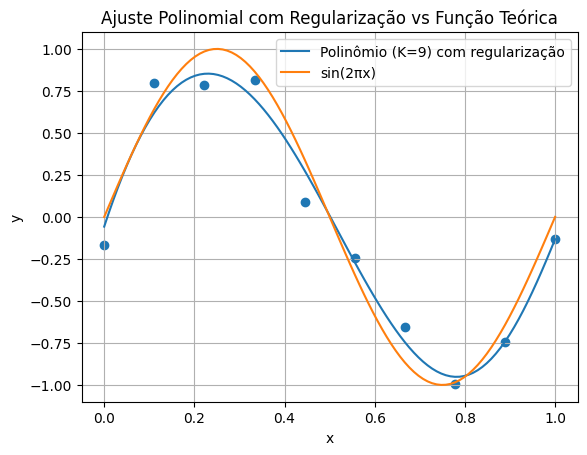

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def polyfit_with_regularization(x, y, degree, lambda_):
    """
    Ajusta um polinômio de grau especificado aos dados (x, y) com regularização L2.

    Parâmetros:
        x (array): Valores da variável independente.
        y (array): Valores da variável dependente.
        degree (int): Grau do polinômio.
        lambda_ (float): Parâmetro de regularização (termo L2).

    Retorna:
        theta (array): Coeficientes do polinômio ajustado.
    """
    # Cria a matriz de design para o polinômio de grau 'degree'
    X = np.vander(x, degree + 1, increasing=True)

    # Define a matriz de regularização (termo L2), ignorando o termo de intercepto
    L = lambda_ * np.eye(degree + 1)
    L[0, 0] = 0  # Não regularizamos o intercepto

    # Resolve o sistema linear (X^T X + L) theta = X^T y
    XtX = X.T @ X
    Xty = X.T @ y
    theta = np.linalg.solve(XtX + L, Xty)

    return theta


# Geração dos dados
N = 10  # Número de pontos de dados
x = np.linspace(0, 1, N)  # Pontos espaçados uniformemente no intervalo [0, 1]
y = np.sin(2 * np.pi * x) + np.random.normal(0, 0.15, N)  # Adiciona ruído gaussiano

# Parâmetros do modelo
K = 9  # Grau do polinômio
lambda_ = 0.0001  # Parâmetro de regularização

# Ajuste do modelo polinomial com regularização
theta = polyfit_with_regularization(x, y, K, lambda_)

# Geração de pontos para a curva ajustada
xr = np.linspace(0, 1, 100)  # Pontos para a curva suave
Xr = np.vander(xr, K + 1, increasing=True)  # Matriz de design para os pontos xr
yr = Xr @ theta  # Valores previstos pelo modelo polinomial

# Geração da curva teórica (seno sem ruído)
yn = np.sin(2 * np.pi * xr)

# Plotagem dos resultados
line1, = plt.plot(xr, yr, label=f'Polinômio (K={K}) com regularização')  # Curva do polinômio ajustado
line2, = plt.plot(xr, yn, label='sin(2πx)')  # Curva teórica da função seno
plt.scatter(x, y, label='Dados com ruído')  # Pontos de dados com ruído

# Configurações do gráfico
plt.legend(handles=[line1, line2])  # Adiciona a legenda ao gráfico
plt.xlabel('x')  # Rótulo do eixo x
plt.ylabel('y')  # Rótulo do eixo y
plt.title('Ajuste Polinomial com Regularização vs Função Teórica')  # Título do gráfico
plt.grid(True)  # Adiciona uma grade ao gráfico
plt.show()  # Exibe o gráfico

Observe a diferença entre os coeficientes do modelos com e sem regularização.
Os valores do modelo regularizado são muito menores.  

In [ ]:
np.set_printoptions(formatter={'float': '{:.2f}'.format})

#print(theta)
print("Regularizado: ", theta[::-1])
print("Não regularizado", polynomial_model.coef)

Regularizado:  [-0.54 -1.45 -1.08 0.96 4.40 6.94 1.90 -19.43 8.23 -0.06]
Não regularizado [-39164.12 178612.52 -342335.99 358135.19 -222114.96 82888.23 -17944.93
 2004.24 -80.01 0.07]


# Erros dos modelos

O código abaixo calcula a raíz quadrada do erro quadrático médio (ERMS) usando conjunto de treino e teste. Lembre-se de que um modelo de aprendizado de máquina deve funcionar em um conjunto de dados independente (aka conjunto de teste) e não apenas no conjunto de treinamento.  

Grau 0: ERMS Treinamento = 0.8313, ERMS Teste = 0.6437
Grau 1: ERMS Treinamento = 0.5044, ERMS Teste = 0.7254
Grau 2: ERMS Treinamento = 0.5024, ERMS Teste = 0.7590
Grau 3: ERMS Treinamento = 0.1738, ERMS Teste = 0.1623
Grau 4: ERMS Treinamento = 0.1738, ERMS Teste = 0.1630
Grau 5: ERMS Treinamento = 0.1657, ERMS Teste = 0.2302
Grau 6: ERMS Treinamento = 0.1653, ERMS Teste = 0.2184
Grau 7: ERMS Treinamento = 0.1622, ERMS Teste = 0.3405
Grau 8: ERMS Treinamento = 0.1576, ERMS Teste = 0.6153
Grau 9: ERMS Treinamento = 0.1184, ERMS Teste = 0.8769


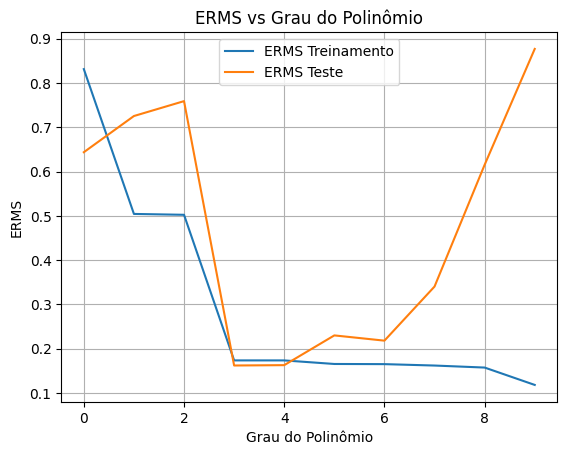

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def erms(y_true, y_pred):
    """
    Calcula o Erro Root Mean Squared (ERMS) entre os valores reais (y_true) e os valores previstos (y_pred).
    """
    mse = np.mean((y_pred - y_true) ** 2)  # Calcula o Mean Squared Error (MSE)
    rms = np.sqrt(mse)  # Calcula a raiz quadrada do MSE para obter o RMSE
    return rms

# Geração dos dados
M = 25  # Número de pontos de dados
X = np.linspace(0, 1, M)  # Pontos espaçados uniformemente no intervalo [0, 1]
y = np.sin(2 * np.pi * X) + np.random.normal(0, 0.2, M)  # Adiciona ruído gaussiano

# Divisão dos dados em conjuntos de treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Listas para armazenar os erros RMS (Root Mean Squared Error)
rms_train = []
rms_test = []

for K in range(0, 10):
    # Ajusta um polinômio de grau 'K' aos dados de treinamento
    mymodel = np.poly1d(np.polyfit(X_train, y_train, K))

    # Previsões nos conjuntos de treinamento e teste
    y_predicted_train = mymodel(X_train)
    y_predicted_test = mymodel(X_test)

    # Calcula o ERMS (Erro Root Mean Squared) para treinamento e teste
    erms_train = erms(y_train, y_predicted_train)
    erms_test = erms(y_test, y_predicted_test)

    # Armazena os valores de ERMS
    rms_train.append(erms_train)
    rms_test.append(erms_test)

    # Exibe o ERMS para cada grau do polinômio
    print(f"Grau {K}: ERMS Treinamento = {erms_train:.4f}, ERMS Teste = {erms_test:.4f}")

# Plotagem dos erros RMS
line1, = plt.plot(range(0, 10), rms_train, label='ERMS Treinamento')
line2, = plt.plot(range(0, 10), rms_test, label='ERMS Teste')

# Configurações do gráfico
plt.legend(handles=[line1, line2])  # Adiciona a legenda ao gráfico
plt.xlabel('Grau do Polinômio')  # Rótulo do eixo x
plt.ylabel('ERMS')  # Rótulo do eixo y
plt.title('ERMS vs Grau do Polinômio')  # Título do gráfico
plt.grid(True)  # Adiciona uma grade ao gráfico
plt.show()  # Exibe o gráfico

#Exercícios

1. Teste a implementação a seguir com diferentes valores de $K$ (0, 1, ..., 9) e observe os resultados.

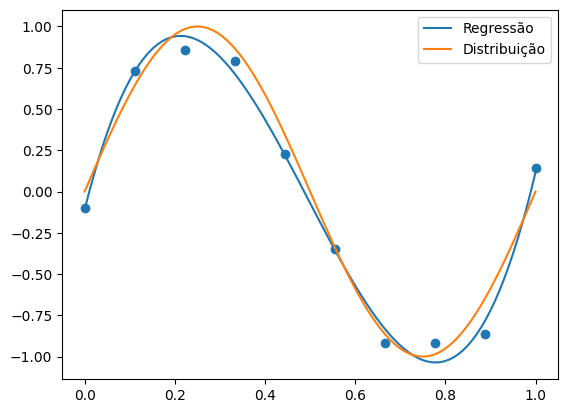

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

N = 10
x = np.linspace(0, 1, N)
y = np.sin(2*np.pi*x) + np.random.normal(0, 0.15, N)

NR = 100
xr = np.linspace(0, 1, NR)
yr = np.sin(2*np.pi*xr)

K = 3 #mude aqui

mymodel = np.poly1d(np.polyfit(x, y, K))


line1, = plt.plot(xr, mymodel(xr), label='Regressão')
line2, = plt.plot(xr, yr, label='Distribuição')

plt.scatter(x, y)
plt.legend(handles=[line1, line2])

2. (**1.0 ponto**) Implemente a regressão polinomial utilizando o framework de aprendizado supervisionado apresentado nas aulas anteriores. Complete a função `cost_function` abaixo para que ela retorne o custo e o gradiente necessários para o treinamento do modelo. Para evitar overfitting, inclua o termo de regularização tanto na função de custo quanto no gradiente.

(30, 9)
(30, 1)


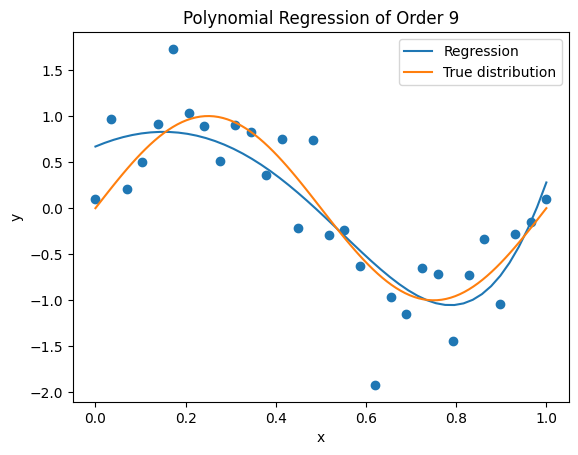

In [ ]:
import scipy.optimize as opt
import numpy as np
import matplotlib.pyplot as plt

def cost_function(theta, X, y, lambda_=0.1):
    """
    Calcula o custo e o gradiente para a regressão linear com regularização.

    Parâmetros:
    theta -- Parâmetros do modelo (vetor 1D)
    X -- Matriz de características (m x n)
    y -- Vetor de valores alvo (m x 1)
    lambda_ -- Parâmetro de regularização (default: 0.1)

    Retorna:
    J -- O valor do custo
    grad -- O vetor de gradiente (1D)
    """
    m = y.size
    h = np.dot(X, theta)

    return J, grad

def optimize_theta(X, y, initial_theta, lambda_=0.1):
    opt_results = opt.minimize(cost_function, initial_theta, args=(X, y, lambda_), method='L-BFGS-B',
                               jac=True, options={'maxiter': 400})
    if not opt_results.success:
        raise RuntimeError("Otimização falhou: " + opt_results.message)
    return opt_results['x'], opt_results['fun']

def feature_normalize(X, mean=None, std=None):
    X = np.array(X)
    if mean is None or std is None:
        mean = np.mean(X, axis=0)
        std = np.std(X, axis=0, ddof=1)
    X = (X - mean) / std
    return X, mean, std

def extend_feature(X_ini, k):
    result = X_ini
    for i in range(2, k+1):
        result = np.hstack((result, np.power(X_ini, i)))
    return result

# Geração de dados
N = 30
x = np.linspace(0, 1, N)
y = np.sin(2*np.pi*x) + np.random.normal(0, 0.5, N)

NR = 100
xr = np.linspace(0, 1, NR)
yr = np.sin(2*np.pi*xr)

m = y.size

# Preparação dos dados
k = 9
X_ini = x.copy()
X_ini = X_ini.reshape(-1, 1)
X = extend_feature(X_ini, k)
X, mean, std = feature_normalize(X)
ones = np.ones((m, 1))
print(X.shape)
print(ones.shape)
X = np.hstack([ones, X])

#X = np.hstack([np.ones((m, 1)), X])  # Correção aplicada aqui
theta = np.random.randn(k + 1)

# Otimização
opt_theta, cost = optimize_theta(X, y, theta)

# Previsão
xnew = np.linspace(0, 1, 50)
xnew = xnew.reshape(-1, 1)
X2 = extend_feature(xnew, k)
X2 = (X2 - mean) / std
X2 = np.hstack([np.ones((xnew.shape[0], 1)), X2])
h = np.dot(X2, opt_theta)

# Visualização
line1, = plt.plot(xnew, h, label='Regression')
line2, = plt.plot(xr, yr, label='True distribution')
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression of Order 9')
plt.legend(handles=[line1, line2])
plt.show()